<a href="https://colab.research.google.com/github/sebastianbosire-code/nasa-exoplanets-analysis/blob/main/nasa_exoplanets_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# imports go here
import pandas as pd
import sqlite3 as sql
import matplotlib.pyplot as plt
import numpy as np

---
#### CS 260 Database and Data Visualization: Final Project
---

NASA EXOPLANETS

By: Tommy Williams & Sebastian Ombati


---

## 1. Introduction

For this project, our group explored the over 5000 exoplanets included in NASA's exoplanet database. We examined the planets' radii, distance from Earth, brightness, discovery year, and eccentricity in order to compare exoplanets to one another and also to planets within our solar system. We were curious to see when the majority of exoplanets were discovered and how they varied from each other. We also compared our initial dataset, with a dataset that showed which discovery facility discovered the most exoplanets.

During our research, we found that the majority of exoplanets have an orbital eccentricity (how circular their orbit is around the sun) between 0 and 0.1, which means their orbits are close to circular. We also found that the few planets orbiting at an Earth-like distance from their star (0.7 to 1.5 AU) are mostly gas giants. Our group also examined exoplanet discovery over time, and we found that there were large spikes of exoplanet discovery in 2014 and 2016, due to Kepler data being processed and analyzed. This discovery led us to analyzing a dataset that included which facility discovered exoplanets. We found that the Kepler Space Telescope led all facilities, with over 2,000 confirmed transit discoveries.

Overall, the majority of our results were not surprising to us. There were a handful of results that were unexpected to us, which led to us digging deeper into these topics to better understand exoplanets.

---




## 2. Data  

A direct link to the data can be found at the following website.
 * https://www.kaggle.com/datasets/adityamishraml/nasaexoplanets


The data was collected from the NASA Exoplanet Archive, which keeps an up-to-date list of all the NASA-discovered exoplanets and information about them. The person who made the database extracted the data from NASA’s website and then preprocessed and cleaned the data.


In [ ]:
#In this cell, we load the data.
try:
    #load the csv data from github
    csv_data = pd.read_csv("https://raw.githubusercontent.com/TommyJW555/Final-Project-CS-260-Tommy-Sebastian/refs/heads/main/nasaexoplanet.csv")

    #Connect to a SQLite database
    conn = sql.connect('exoplanets.db')

    #Load the csv data into a table in the database
    csv_data.to_sql('exoplanets', conn, index = False)

except ValueError:
    print("""A ValueError occurred. If you've run this cell twice,
             then you're likely getting the error because the DB was created the first time
             and Python doesn't want to overwrite it the second time.""")

A ValueError occurred. If you've run this cell twice,
             then you're likely getting the error because the DB was created the first time
             and Python doesn't want to overwrite it the second time.


In [ ]:

# Load the confirmed exoplanets CSV into a DataFrame
confirmed_df = pd.read_csv("confirmed_exoplanets.csv")

# Store it as a SQL table named confirmed_exoplanets
confirmed_df.to_sql("confirmed_exoplanets", conn, if_exists="replace", index=False)


4126

In [ ]:
#Show the rows of the table.
sql_statement = """SELECT *
                   FROM exoplanets"""

dataset_all = pd.read_sql_query(sql_statement, conn)
dataset_all

,name,distance,brightness,planet_type,discovery_year,mass_multiplier,mass_comparison,radius_multiplier,radius_comparison,orbital_radius,orbital_period,eccentricity,detection_method
0,11 Comae Berenices b,304.0,4.72307,Gas Giant,2007,19.40000,Jupiter,1.080,Jupiter,1.290000,0.892539,0.23,Radial Velocity
1,11 Ursae Minoris b,409.0,5.01300,Gas Giant,2009,14.74000,Jupiter,1.090,Jupiter,1.530000,1.400000,0.08,Radial Velocity
2,14 Andromedae b,246.0,5.23133,Gas Giant,2008,4.80000,Jupiter,1.150,Jupiter,0.830000,0.508693,0.00,Radial Velocity
3,14 Herculis b,58.0,6.61935,Gas Giant,2002,8.13881,Jupiter,1.120,Jupiter,2.773069,4.800000,0.37,Radial Velocity
4,16 Cygni B b,69.0,6.21500,Gas Giant,1996,1.78000,Jupiter,1.200,Jupiter,1.660000,2.200000,0.68,Radial Velocity
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5245,XO-7 b,764.0,10.52100,Gas Giant,2019,0.70900,Jupiter,1.373,Jupiter,0.044210,0.007940,0.04,Transit
5246,YSES 2 b,357.0,10.88500,Gas Giant,2021,6.30000,Jupiter,1.140,Jupiter,115.000000,1176.500000,0.00,Direct Imaging
5247,YZ Ceti b,12.0,12.07400,Terrestrial,2017,0.70000,Earth,0.913,Earth,0.016340,0.005476,0.06,Radial Velocity
5248,YZ Ceti c,12.0,12.07400,Super Earth,2017,1.14000,Earth,1.050,Earth,0.021560,0.008487,0.00,Radial Velocity


2.1 Summary of Variables within the Exoplanets Table

The Exoplanet table has 13 columns/variables and 5250 rows.  All variables are explained in this section.

Note that the table was read in from a csv, but had we created a formal SQLite database for the table, the schema would have been as follows.

```
DROP TABLE IF EXISTS exoplanets;
CREATE TABLE "exoplanets" (
  'name' TEXT,
  'distance' REAL,
  'brightness' REAL,
  'planet_type' TEXT NOT NULL,
  'discovery_year' INTEGER NOT NULL,
  'mass_multiplier' REAL,
  'mass_comparison' TEXT,
  'radius_multiplier' REAL,
  'radius_comparison' TEXT,
  'orbital_radius' REAL,
  'orbital_period' REAL,
  'eccentricity' REAL,
  'detection_method' TEXT NOT NULL,
  PRIMARY KEY('name')
);
```

Here are the variables, their descriptions, their units, their types, and some descriptive statistics.

CATEGORICAL VARIABLES

name – unique planet identifier (catalog name)
  Number of missing values: 0
  Units: None
  Contains 5,250 distinct values
  Notes: Serves as the primary key (unique across the table).

planet_type – coarse planet classification
  Number of missing values: 0
  Units: None
  Contains 5 distinct values:
  Gas Giant, Neptune-like, Super Earth, Terrestrial, Unknown
  Notes: Unknown captures unclassified objects.

mass_comparison – reference body for the mass multiplier
  Number of missing values: 23
  Units: None
  Contains 2 distinct values: Earth, Jupiter
  Notes: When missing, mass_multiplier still may be present but its reference is unspecified.

radius_comparison – reference body for the radius multiplier
  Number of missing values: 17
  Units: None
  Contains 2 distinct values: Earth, Jupiter
  Notes: When missing, radius_multiplier still may be present but its reference is unspecified.

detection_method – technique used to discover the planet
  Number of missing values: 0
  Units: None
  Contains 11 distinct values:
  Astrometry, Direct Imaging, Disk Kinematics, Eclipse Timing Variations,
  Gravitational Microlensing, Orbital Brightness Modulation, Pulsar Timing,
  Pulsation Timing Variations, Radial Velocity, Transit, Transit Timing Variations

Quantitative Continuous Varibles

distance – distance to the host system
  number of missing values: 17
  Units: light-years (typical for this dataset)
  max value: 27,727.0
  min value: 4.0
  average value: 2,167.17
  Notes: Long right tail; a small number of very distant systems dominate the mean.

brightness – apparent stellar magnitude of the host star
  number of missing values: 161
  Units: magnitudes (mag)
  max value: 44.61
  min value: 0.872
  average value: 12.684
  Notes: Magnitude is logarithmic (lower = brighter); treat with care in averages.

mass_multiplier – planet mass relative to the comparison body
  number of missing values: 23
  Units: × (unitless multiple), relative to mass_comparison
  max value: 752.0
  min value: 0.02
  average value: 6.435

radius_multiplier – planet radius relative to the comparison body
  number of missing values: 17
  Units: × (unitless multiple), relative to radius_comparison
  max value: 6.9
  min value: 0.2
  average value: 1.015

orbital_radius – semi-major axis of the orbit
  number of missing values: 289
  Units: astronomical units (AU)
  max value: 7,506.0
  min value: 0.0044
  average value: 6.963
  Notes: Heavy right tail; many short-period systems at very small AU.

orbital_period – orbital period
  number of missing values: 0
  Units: days (typical for exoplanet catalogs)
  max value: 1,101,369.9
  min value: 0.0002737851
  average value: 479.151
  Notes: Extreme range (from hours to millennia); consider log scale for plots.

eccentricity – orbital eccentricity (0=circular, →1 highly elliptical)
  number of missing values: 0
  Units: unitless
  max value: 0.95
  min value: −0.52
  average value: 0.0636
  Notes: A few negative entries exist (likely data/cleaning errors); clamp to [0,1] or mark as missing before strict validation.


Quantitative Discrete Varibles

discovery_year – year the planet was discovered
  number of missing values: 0
  Units: year
  min value: 1992
  max value: 2023
  average value: 2015.73
  Notes: Coverage spans early exoplanet era to 2023; growth accelerates post-2009 (Kepler era).


### 2.2 Code used to Summarize Variables

In this section we include the code used to describe the variables in the previous section.


In [ ]:
#Get the distinct values in the name column
sql_statement = """
                    SELECT DISTINCT(name)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,name
0,11 Comae Berenices b
1,11 Ursae Minoris b
2,14 Andromedae b
3,14 Herculis b
4,16 Cygni B b
...,...
5245,XO-7 b
5246,YSES 2 b
5247,YZ Ceti b
5248,YZ Ceti c


In [ ]:
#Get the min, max, average, and number of missing values in the name column.
sql_statement = """
                     SELECT COUNT(*) - COUNT(name) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,missing_values
0,0


In [ ]:
#Get the distinct values in the distance column
sql_statement = """
                    SELECT DISTINCT(distance)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,distance
0,304.0
1,409.0
2,246.0
3,58.0
4,69.0
...,...
2538,494.0
2539,695.0
2540,889.0
2541,768.0


In [ ]:
#Get the min, max, average, and number of missing values in the distance column.
sql_statement = """
                    SELECT MIN(distance), MAX(distance), AVG(distance),
                           COUNT(*) - COUNT(distance) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(distance),MAX(distance),AVG(distance),missing_values
0,4.0,27727.0,2167.168737,17


In [ ]:
#Get the distinct values in the brightness column
sql_statement = """
                    SELECT DISTINCT(brightness)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,brightness
0,4.72307
1,5.01300
2,5.23133
3,6.61935
4,6.21500
...,...
2871,9.85400
2872,10.81400
2873,10.52100
2874,10.88500


In [ ]:
#Get the min, max, average, and number of missing values in the brightness column.
sql_statement = """
                    SELECT MIN(brightness), MAX(brightness), AVG(brightness),
                           COUNT(*) - COUNT(brightness) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(brightness),MAX(brightness),AVG(brightness),missing_values
0,0.872,44.61,12.683738,161


In [ ]:
#Get the distinct values in the planet_type column
sql_statement = """
                    SELECT DISTINCT(planet_type)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,planet_type
0,Gas Giant
1,Super Earth
2,Neptune-like
3,Terrestrial
4,Unknown


In [ ]:
#Get the min, max, average, and number of missing values in the planet_type column.
sql_statement = """
                     SELECT COUNT(*) - COUNT(planet_type) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,missing_values
0,0


In [ ]:
#Get the distinct values in the discovery_year column
sql_statement = """
                    SELECT DISTINCT(discovery_year)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,discovery_year
0,2007
1,2009
2,2008
3,2002
4,1996
5,2020
6,2018
7,2010
8,2021
9,2013


In [ ]:
#Get the min, max, average, and number of missing values in the discovery_year column.
sql_statement = """
                    SELECT MIN(discovery_year), MAX(discovery_year), AVG(discovery_year),
                           COUNT(*) - COUNT(discovery_year) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(discovery_year),MAX(discovery_year),AVG(discovery_year),missing_values
0,1992,2023,2015.73219,0


In [ ]:
#Get the distinct values in the mass_multiplier column
sql_statement = """
                    SELECT DISTINCT(mass_multiplier)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,mass_multiplier
0,19.40000
1,14.74000
2,4.80000
3,8.13881
4,1.78000
...,...
1717,0.92200
1718,0.59200
1719,0.73100
1720,7.29000


In [ ]:
#Get the min, max, average, and number of missing values in the mass_multiplier column.
sql_statement = """
                    SELECT MIN(mass_multiplier), MAX(mass_multiplier), AVG(mass_multiplier),
                           COUNT(*) - COUNT(mass_multiplier) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(mass_multiplier),MAX(mass_multiplier),AVG(mass_multiplier),missing_values
0,0.02,752.0,6.434812,23


In [ ]:
#Get the distinct values in the mass_comparison column
sql_statement = """
                    SELECT DISTINCT(mass_comparison)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,mass_comparison
0,Jupiter
1,Earth
2,None


In [ ]:
#Get the min, max, average, and number of missing values in the mass_comparison column.
sql_statement = """
                     SELECT COUNT(*) - COUNT(mass_comparison) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,missing_values
0,23


In [ ]:
#Get the distinct values in the radius_multiplier column
sql_statement = """
                    SELECT DISTINCT(radius_multiplier)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,radius_multiplier
0,1.080
1,1.090
2,1.150
3,1.120
4,1.200
...,...
1028,0.928
1029,1.031
1030,1.159
1031,2.043


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Get the min, max, average, and number of missing values in the radius_multiplier column.
sql_statement = """
                    SELECT MIN(radius_multiplier), MAX(radius_multiplier), AVG(radius_multiplier),
                           COUNT(*) - COUNT(radius_multiplier) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(radius_multiplier),MAX(radius_multiplier),AVG(radius_multiplier),missing_values
0,0.2,6.9,1.015121,17


In [ ]:
#Get the distinct values in the radius_comparison column
sql_statement = """
                    SELECT DISTINCT(radius_comparison)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,radius_comparison
0,Jupiter
1,Earth
2,None


In [ ]:
#Get the min, max, average, and number of missing values in the radius_comparison column.
sql_statement = """
                     SELECT COUNT(*) - COUNT(radius_comparison) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,missing_values
0,17


In [ ]:
#Get the distinct values in the orbital_radius column
sql_statement = """
                    SELECT DISTINCT(orbital_radius)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,orbital_radius
0,1.290000
1,1.530000
2,0.830000
3,2.773069
4,1.660000
...,...
2823,0.055240
2824,0.044210
2825,115.000000
2826,0.016340


In [ ]:
#Get the min, max, average, and number of missing values in the orbital_radius column.
sql_statement = """
                    SELECT MIN(orbital_radius), MAX(orbital_radius), AVG(orbital_radius),
                           COUNT(*) - COUNT(orbital_radius) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(orbital_radius),MAX(orbital_radius),AVG(orbital_radius),missing_values
0,0.0044,7506.0,6.962942,289


In [ ]:
#Get the distinct values in the orbital_period column
sql_statement = """
                    SELECT DISTINCT(orbital_period)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,orbital_period
0,0.892539
1,1.400000
2,0.508693
3,4.800000
4,2.200000
...,...
1273,130.700000
1274,0.594661
1275,0.374538
1276,0.330732


In [ ]:
#Get the min, max, average, and number of missing values in the orbital_period column.
sql_statement = """
                    SELECT MIN(orbital_period), MAX(orbital_period), AVG(orbital_period),
                           COUNT(*) - COUNT(orbital_period) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(orbital_period),MAX(orbital_period),AVG(orbital_period),missing_values
0,0.000274,1101369.9,479.150875,0


In [ ]:
#Get the distinct values in the eccentricity column
sql_statement = """
                    SELECT DISTINCT(eccentricity)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,eccentricity
0,0.230
1,0.080
2,0.000
3,0.370
4,0.680
...,...
173,0.068
174,0.043
175,0.022
176,0.059


In [ ]:
#Get the min, max, average, and number of missing values in the eccentricity column.
sql_statement = """
                    SELECT MIN(eccentricity), MAX(eccentricity), AVG(eccentricity),
                           COUNT(*) - COUNT(eccentricity) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,MIN(eccentricity),MAX(eccentricity),AVG(eccentricity),missing_values
0,-0.52,0.95,0.063568,0


In [ ]:
#Get the distinct values in the detection_method column
sql_statement = """
                    SELECT DISTINCT(detection_method)
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,detection_method
0,Radial Velocity
1,Direct Imaging
2,Eclipse Timing Variations
3,Transit
4,Astrometry
5,Disk Kinematics
6,Transit Timing Variations
7,Orbital Brightness Modulation
8,Pulsation Timing Variations
9,Gravitational Microlensing


In [ ]:
#Get the min, max, average, and number of missing values in the detection_method column.
sql_statement = """
                     SELECT COUNT(*) - COUNT(detection_method) AS missing_values
                    FROM exoplanets
                """

results = pd.read_sql_query(sql_statement, conn)
results

,missing_values
0,0


---

## 3. Analysis

When looking into this dataset, we decided to focus on orbital radius, discovery year, discovery type, planet type, eccentricity, brightness, and distance. We found that the types of exoplanets discovered by the transit detection method, and the discovery of all exoplanets over time, followed a very similar trend, and had similar peaks in 2014 and 2016. We also found that the majority of exoplanets have an eccentricity between 0 and 0.1, and as the eccentricity increases, there are fewer planets in the bins. The apparent magnitude of a planet's host star has a moderate positive correlation with its distance from Earth (r = 0.64), meaning farther stars tend to appear dimmer. Finally, our accompanying dataset shows that the Kepler Space Telescope is the facility that discovered the most exoplanets.


### 3.1 Q: How many “just-right orbit” planets are in our data, and what planet types are they?

Because we don’t have stellar temperature data, we’re using a classroom proxy: planets with an orbital_radius between 0.7 AU and 1.5 AU.
We’ll group those by planet_type to see which kinds of planets most often appear in that “just-right” zone, to see which categories of planets are most common in potentially habitable orbits.

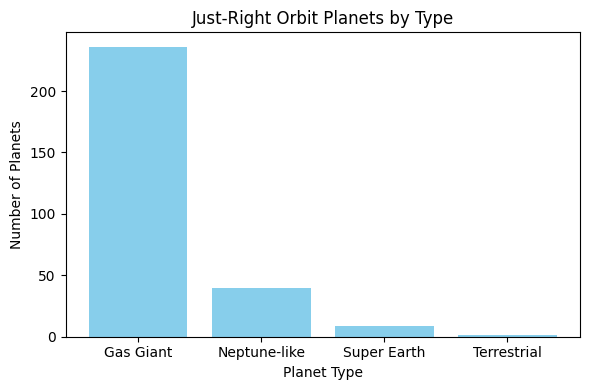

In [ ]:
import matplotlib.pyplot as plt

data = dataset_all.dropna(subset=["orbital_radius", "planet_type"])
just_right = data[(data["orbital_radius"] >= 0.7) & (data["orbital_radius"] <= 1.5)]
counts = just_right["planet_type"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values, color="skyblue")
plt.title("Just-Right Orbit Planets by Type")
plt.xlabel("Planet Type")
plt.ylabel("Number of Planets")
plt.tight_layout()
plt.show()

After graphing the data, we found that only a small number of planets fall within the 0.7–1.5 AU “just-right orbit” range. Most of these are classified as gas giants, with far fewer Neptune-like or smaller planets. This suggests that even planets orbiting at Earth-like distances don’t necessarily resemble Earth in size or composition. It also shows a likely detection bias in the dataset; planets with shorter orbits are easier to observe, so we see fewer in this mid-range.

*Contributor: Sebastian Ombati (question, graph, and write-up)*

### 3.2 Q: As time goes on, are more or fewer planets discovered by transit?

###     1. discovery_year
###     2. detection_method

We want to see the trend in transit discovery over time. We will do this by analyzing the relationship between discovery_year and detection_method, specifically the transit detection method

In [ ]:
# Calculate the number of transit discoveries per year
sql_statement = """
    SELECT discovery_year, COUNT(*) AS transit_discoveries
    FROM exoplanets
    WHERE detection_method = 'Transit'
    GROUP BY discovery_year
    ORDER BY discovery_year
"""

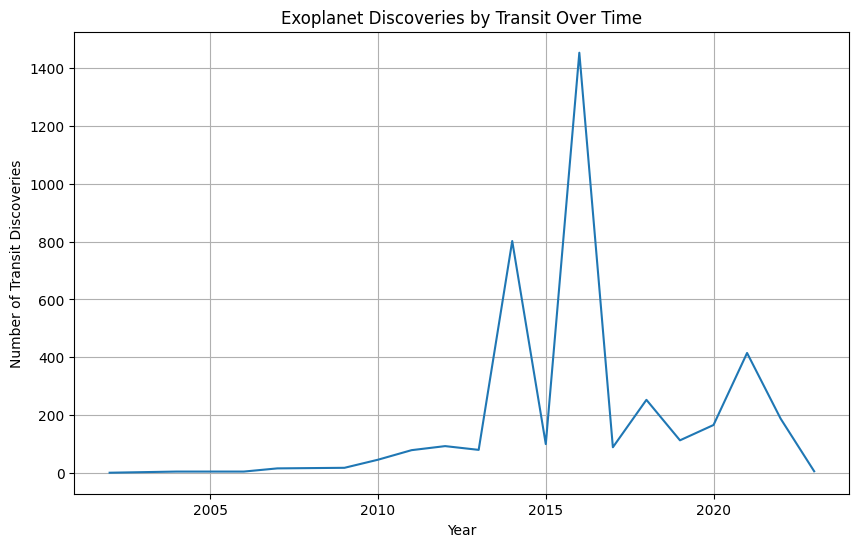

In [ ]:
# Graph code for creating a line graph of transit discoveries over time.

transit_discoveries_by_year = pd.read_sql_query(sql_statement, conn)

# Create the line plot
plt.figure(figsize=(10, 6))
plt.plot(transit_discoveries_by_year['discovery_year'], transit_discoveries_by_year['transit_discoveries'])
plt.title('Exoplanet Discoveries by Transit Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Transit Discoveries')
plt.grid(True)
plt.show()

We learned that the transit detection method was used very few times for about 15 years in exoplanet discovery, but in the mid-2010s, the transit detection method spiked. The year 2016 had by far the most transit-discovered exoplanets, at over 1,400. The transit method then fell off quite a bit in the late 2010s and early 2020s. This left us wondering why there was such a dramatic spike in 2014 and 2016. Our thought was that it could have been a time where NASA focused their attention on the transit method, which is observing an exoplanet by seeing it pass in front of a star. We found out that it was due to the Kepler Space Telescope data being processed and analyzed at this time.

*Contributor: Tommy Williams (question, graph, and write-up)*

### 3.3 Q: What is the distribution of eccentricity? Are orbits closer to being circular or oblong?

1. eccentricity



We want to find the distribution of the exoplanets' orbit eccentricity, which is how circular the planet's orbit is around the star. We will do this by making a histogram showing the eccentricity values, and what percentage of each eccentricity value the planets have.

In [ ]:
multipliers_eccentricity = 100.0 * np.ones(len(dataset_all)) / len(dataset_all)
multipliers_eccentricity

array([0.01904762, 0.01904762, 0.01904762, ..., 0.01904762, 0.01904762,
       0.01904762])

/tmp/ipython-input-458644312.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


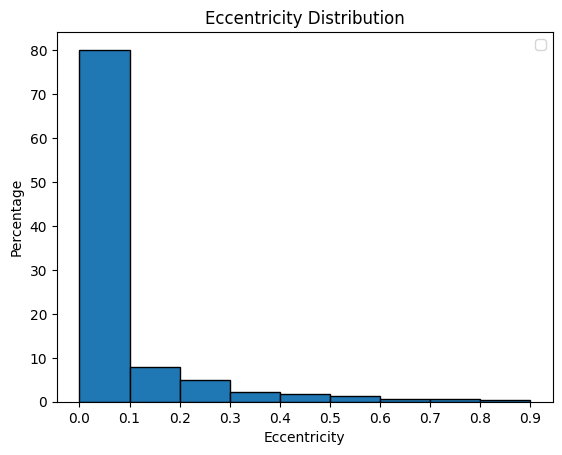

In [ ]:
output = plt.hist(dataset_all['eccentricity'], bins=np.arange(0, 1, 0.1), weights = multipliers_eccentricity, edgecolor='black')

plt.xticks(np.arange(0,1,0.1))
plt.xlabel('Eccentricity')
plt.ylabel('Percentage')
plt.title('Eccentricity Distribution')
plt.legend()
output
plt.show()

This graph shows us that almost 80% of the exoplanets have an eccentricity between 0 and 0.1, which means their orbits are close to circular. The following bins are all lower than 10%, and as orbits become more oblong (higher eccentricity), there are fewer planets in each bin. This fits with how planetary systems tend to settle into near-circular orbits over time, and it is also easier to detect planets on stable, short, near-circular orbits. This data was not surprising to us.

*Contributor: Tommy Williams (question, graph, and write-up)*

### 3.4 Q: Is there a relationship between brightness and distance?

1. brightness
2. distance

We want to see if there is a relationship between the brightness of the exoplanets, and their distance, in lightyears, away from Earth. To do this, we will make a scatterplot with distance and brightness values. We will also remove any outliers so our data is easier to read and interpret.

In [ ]:
# SQL query to remove outliers based on visual inspection of the scatter plot
sql_statement_cleaned = """
    SELECT *
    FROM exoplanets
    WHERE distance < 5000 AND brightness < 20
"""

cleaned_dataset = pd.read_sql_query(sql_statement_cleaned, conn)
display(cleaned_dataset.head())

,name,distance,brightness,planet_type,discovery_year,mass_multiplier,mass_comparison,radius_multiplier,radius_comparison,orbital_radius,orbital_period,eccentricity,detection_method
0,11 Comae Berenices b,304.0,4.72307,Gas Giant,2007,19.40000,Jupiter,1.08,Jupiter,1.290000,0.892539,0.23,Radial Velocity
1,11 Ursae Minoris b,409.0,5.01300,Gas Giant,2009,14.74000,Jupiter,1.09,Jupiter,1.530000,1.400000,0.08,Radial Velocity
2,14 Andromedae b,246.0,5.23133,Gas Giant,2008,4.80000,Jupiter,1.15,Jupiter,0.830000,0.508693,0.00,Radial Velocity
3,14 Herculis b,58.0,6.61935,Gas Giant,2002,8.13881,Jupiter,1.12,Jupiter,2.773069,4.800000,0.37,Radial Velocity
4,16 Cygni B b,69.0,6.21500,Gas Giant,1996,1.78000,Jupiter,1.20,Jupiter,1.660000,2.200000,0.68,Radial Velocity


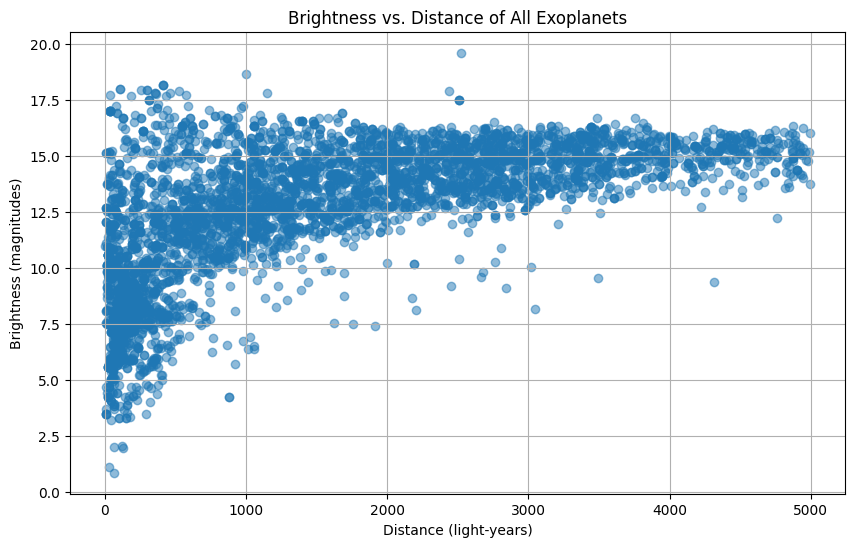

In [ ]:
# Create a scatter plot of brightness vs. distance using the cleaned dataset
plt.figure(figsize=(10, 6))
plt.scatter(cleaned_dataset['distance'], cleaned_dataset['brightness'], alpha=0.5)
plt.title('Brightness vs. Distance of All Exoplanets')
plt.xlabel('Distance (light-years)')
plt.ylabel('Brightness (magnitudes)')
plt.grid(True)
plt.show()

In [ ]:
#correlation table
corr_brightness_distance = cleaned_dataset.corr(numeric_only = True)

#pull out the correlation coefficient for brightness and distance
corr_brightness_distance = corr_brightness_distance.loc['brightness', 'distance']
corr_brightness_distance

np.float64(0.6419084871298125)

We removed a handful of outliers (systems farther than 5,000 light-years or with a magnitude of 20 or higher) so we could more closely analyze the majority of the exoplanets in our dataset. In the cleaned data, the correlation coefficient between distance and brightness is 0.642, which is a moderate positive relationship. Because brightness here is measured in magnitudes, where a higher number means a dimmer star, this means host stars that are farther from Earth tend to appear dimmer. This matched our expectation. The relationship is not perfect, though, which suggests other factors, such as how luminous each star actually is, also affect how bright it looks from Earth.

*Contributor: Tommy Williams (question, graph, and write-up)*

### 3.5 Q: How has the number of discovered planets changed over time?

1. names
2. discovery_year

We wanted to see the amount of planets discovered from 1992 to 2023 to see if more or less exoplanets were discovered over time. To do this, we will take the count of planets discovered in each year, and make a line graph to analyze trends.

In [ ]:
# SQL query to get the count of planets discovered in each year
sql_statement = """
    SELECT discovery_year, COUNT(*) AS planet_count
    FROM exoplanets
    GROUP BY discovery_year
    ORDER BY discovery_year
"""

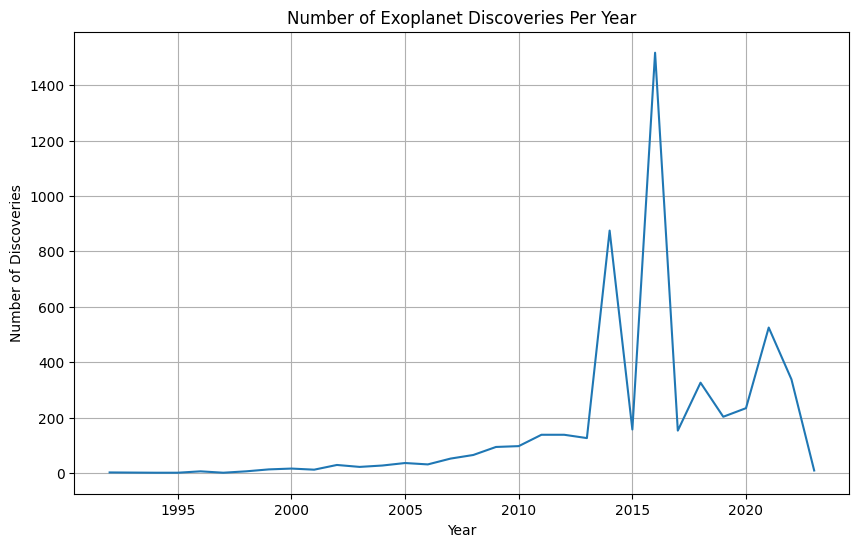

In [ ]:
# Execute the SQL query and load the results into a pandas DataFrame
planet_discoveries_by_year = pd.read_sql_query(sql_statement, conn)

plt.figure(figsize=(10, 6))
plt.plot(planet_discoveries_by_year['discovery_year'], planet_discoveries_by_year['planet_count'])
plt.title('Number of Exoplanet Discoveries Per Year')
plt.xlabel('Year')
plt.ylabel('Number of Discoveries')
plt.grid(True)
plt.show()

This graph is similar to our previous graph about transit discoveries over time due to the spikes at 2014 and 2016, as well as the falloff in recent years. This means that the trends in transit discoveries and overall discoveries correlate. There was a steady rise in exoplanet discoveries for the first 20 years. This data did not surprise us due to what we learned about discovery trends in our previous graph.

*Contributor: Tommy Williams (question, graph, and write-up)*

### 3.6 Q: Which mission contributed most to exoplanet discoveries using the transit method?


The bar chart displays the top 10 space facilities responsible for discovering exoplanets using the Transit method. The data combines two datasets using an inner join on planet name, and filters only confirmed Transit-based discoveries.

In [ ]:
#from google.colab import files
#uploaded = files.upload()

In [ ]:
try:
    #Read in the needed csvs and create the DB
    discovery = pd.read_csv('confirmed_exoplanets.csv')


except sql.Error as error:
    print("Issue during DB creation/connection")
    print(error)

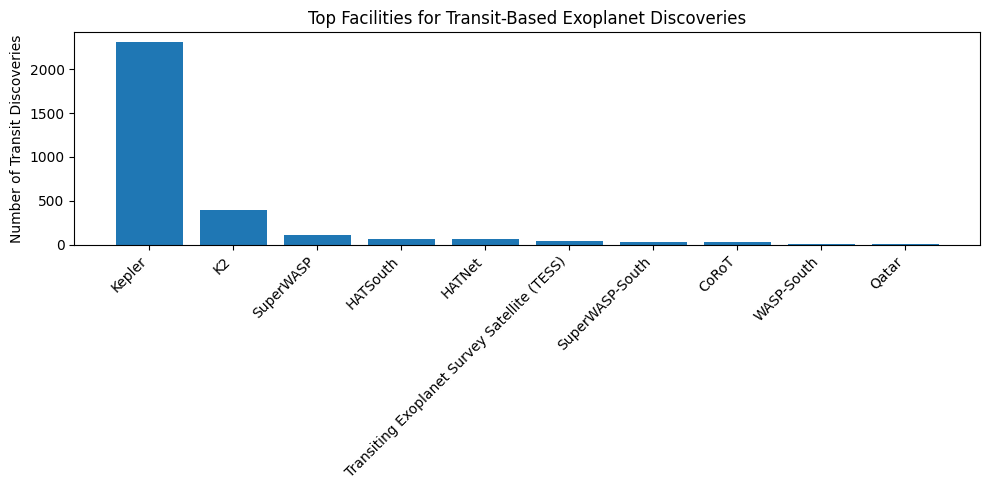

In [ ]:
confirmed = pd.read_csv("confirmed_exoplanets.csv")

confirmed.to_sql('confirmed', conn, index=False, if_exists='replace')

sql_statement = """
SELECT
    c.pl_facility,
    COUNT(*) AS num_transit_planets
FROM
    exoplanets e
JOIN
    confirmed c
ON
    e.name = c.pl_name
WHERE
    c.pl_discmethod = 'Transit'
GROUP BY
    c.pl_facility
ORDER BY
    num_transit_planets DESC
"""
transit_facilities = pd.read_sql_query(sql_statement, conn)
transit_facilities.head(10)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(transit_facilities['pl_facility'][:10], transit_facilities['num_transit_planets'][:10])
plt.xticks(rotation=45, ha='right')
plt.ylabel("Number of Transit Discoveries")
plt.title("Top Facilities for Transit-Based Exoplanet Discoveries")
plt.tight_layout()
plt.show()

We learned that the Kepler Space Telescope overwhelmingly leads in Transit-based exoplanet discoveries, with over 2,000 confirmed planets, far more than any other mission. K2, its follow-up mission, ranks second. This shows that dedicated transit surveys like Kepler have been the most productive in identifying new worlds outside our solar system. Smaller contributions from missions like TESS, SuperWASP, and HATNet show that ground-based and newer space missions continue to expand the known exoplanet population.

### 3.7 Q: What is the distribution of radius multipliers among all the exoplanets?

1. radius_multiplier

We are examining how the radius multipliers of exoplanets are distributed to understand the relative sizes of planets in the dataset. By visualizing this with a histogram, we aimed to identify whether most exoplanets are Earth-sized, larger gas giants, or smaller terrestrial planets.

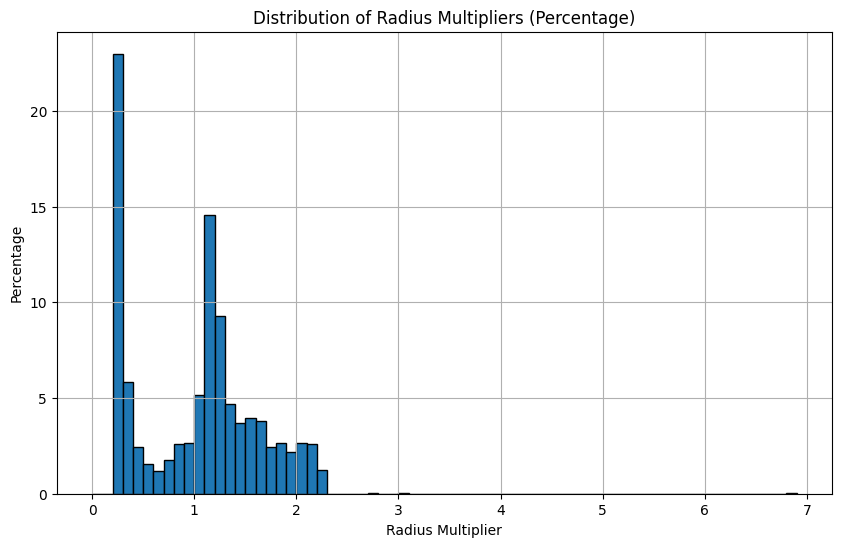

In [ ]:
# Create a histogram of the radius_multiplier column with percentages
plt.figure(figsize=(10, 6))

# Calculate weights for percentages, handling missing values
weights = 100.0 * np.ones(len(dataset_all['radius_multiplier'].dropna())) / len(dataset_all['radius_multiplier'].dropna())

# Define bins - let's try a range that captures the common values and extends to the max
bins = np.arange(0, dataset_all['radius_multiplier'].max() + 0.1, 0.1) # Start from 0, go up to max with steps of 0.1. Adjust step if needed.

plt.hist(dataset_all['radius_multiplier'].dropna(), bins=bins, weights=weights, edgecolor='black')
plt.title('Distribution of Radius Multipliers (Percentage)')
plt.xlabel('Radius Multiplier')
plt.ylabel('Percentage')
plt.grid(True)
plt.show()

From the histogram, we found that the majority of radius multipliers fall between 0 and 1.0, with a secondary spike around 1.1 to 1.2. Beyond that, the frequency drops off sharply, with only a few outliers around 3 and near 7.

One important caveat: radius_multiplier is measured relative to either Earth or Jupiter (see the radius_comparison column), so a value of 1.0 can mean Earth-sized or Jupiter-sized. Because this histogram mixes both scales, it shows how planets compare to their reference body rather than their true size. A stronger follow-up would convert every value to Earth radii (1 Jupiter radius is about 11.2 Earth radii) before plotting, which would give a clearer picture of how common small versus large planets really are.

### 3.8 Q: Were more or fewer Neptune-like planets discovered over the years?

1. planet_type
2. discovery_year

We want to see the trend in Neptune-like planets being discovered over the years. To do this, we will make a line graph comparing the neptune-like planet type with the discovery year.

In [ ]:
# SQL statement to count Neptune-like planets discovered each year
sql_statement_neptune = """
    SELECT discovery_year, COUNT(*) AS neptune_like_count
    FROM exoplanets
    WHERE planet_type = 'Neptune-like'
    GROUP BY discovery_year
    ORDER BY discovery_year
"""

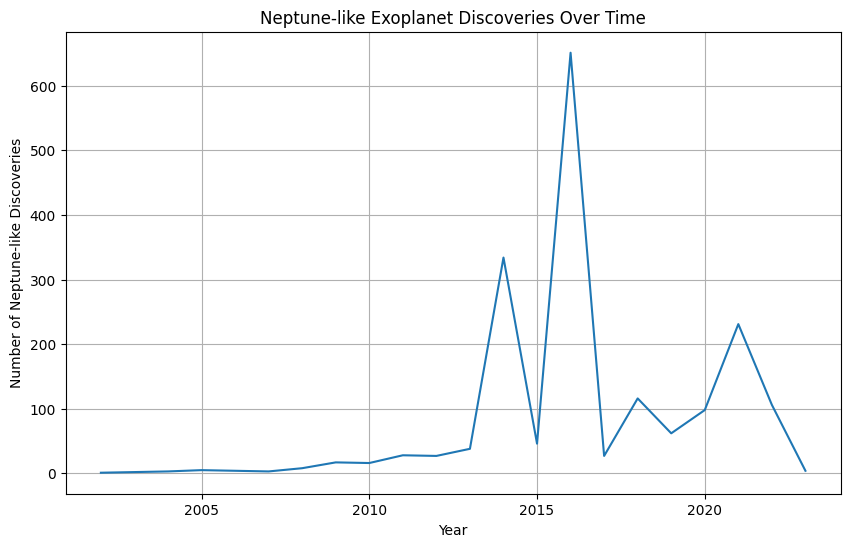

In [ ]:
# Execute the SQL query and load the results into a pandas DataFrame
neptune_discoveries_by_year = pd.read_sql_query(sql_statement_neptune, conn)

# Create the line plot
plt.figure(figsize=(10, 6))
plt.plot(neptune_discoveries_by_year['discovery_year'], neptune_discoveries_by_year['neptune_like_count'])
plt.title('Neptune-like Exoplanet Discoveries Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Neptune-like Discoveries')
plt.grid(True)
plt.show()

This graph is once again similar to the other line graphs. This means that any line graphs comparing discoveries over time would likely all be the same. Like we previously said, the Kepler Data was uploaded around the time the spikes happen, which also affects the Neptune-like planet. We are curious if there are any outlier planet types that do not follow the trend. A neptune-like planet is defined by Nasa as a planet that is similar in size to Neptune and Uranus. Neptune is 4 times the size, or radius, of Earth and almost 17 times its mass (Nasa 2024).

### 3.9 Q: Which discovery facility found the most oblong orbits?

For this section, we focused on the relationship between discovery facility and orbital eccentricity, specifically which facilities have discovered the most planets with oblong orbits (eccentricity > 0.5).

In [ ]:
#from google.colab import files
#uploaded = files.upload()

In [ ]:
try:
    #Read in the needed csvs and create the DB
    discovery = pd.read_csv('confirmed_exoplanets.csv')


except sql.Error as error:
    print("Issue during DB creation/connection")
    print(error)

In [ ]:
ecc_threshold = 0.5  # what you consider an "oblong" orbit

sql_statement = """
SELECT
    confirmed_exoplanets.pl_facility,
    COUNT(confirmed_exoplanets.pl_name) AS num_oblong_planets
FROM confirmed_exoplanets LEFT JOIN exoplanets
    ON confirmed_exoplanets.pl_name = exoplanets.name
WHERE
    confirmed_exoplanets.pl_orbeccen IS NOT NULL
    AND confirmed_exoplanets.pl_orbeccen > ?
GROUP BY
    confirmed_exoplanets.pl_facility
ORDER BY
    num_oblong_planets DESC;
"""

oblong_facilities = pd.read_sql_query(sql_statement, conn, params=[ecc_threshold])
oblong_facilities


,pl_facility,num_oblong_planets
0,La Silla Observatory,27
1,Multiple Observatories,15
2,W. M. Keck Observatory,14
3,Lick Observatory,7
4,Kepler,7
5,Las Campanas Observatory,5
6,Haute-Provence Observatory,5
7,HATSouth,5
8,McDonald Observatory,3
9,Anglo-Australian Telescope,3


### Further Investigation

Existing Documentation

Previous studies from NASA’s Exoplanet Archive and the American Astronomical Society show that high-eccentricity planets are more commonly detected using radial velocity surveys. However, there is little direct comparison of individual discovery facilities and their tendencies to detect oblong orbits, making this a relationship that has not been widely studied.


New Unanswered Questions Created From This Investigation

1.   Why does La Silla Observatory detect more high-eccentricity planets than other facilities?

2.   Are certain detection methods more likely to find oblong orbits?


3.   Do high-eccentricity planets form more often around specific types of stars?

----

## 4. Conclusion

In conclusion, our exoplanet analysis revealed several interesting trends and patterns. We observed that planets within the “just-right orbit” range of 0.7 to 1.5 AU are rare, and most of these are gas giants. This shows that being at an Earth-like distance from a star does not mean a planet will have an Earth-like size or composition. Additionally, the majority of exoplanets have low eccentricities, meaning they have near-circular orbits. Our look at planetary radii suggested that smaller radius multipliers are most common, but because those values are measured against either Earth or Jupiter, converting them to a single unit is an important next step before drawing firm conclusions about planet size.

We also identified clear patterns in exoplanet discovery over time. The transit detection method, especially through the Kepler Space Telescope and its follow-up K2 mission, accounted for the largest share of discoveries. Large spikes in 2014 and 2016 correspond with the processing of Kepler data, and these spikes were mirrored in overall discovery trends, confirming the strong influence of transit-based surveys. We also found a moderate positive correlation (r = 0.642) between distance and apparent magnitude, meaning farther host stars tend to appear dimmer, while the spread in the data shows that factors such as each star's true luminosity also play a role.

The questions raised in our further investigation, such as why La Silla Observatory detects more high-eccentricity planets, whether certain detection methods are more likely to identify oblong orbits, and whether high-eccentricity planets form more often around specific types of stars, are possibilities for future exploration. Extending the dataset to include more recent discoveries or integrating additional detection methods could further clarify these patterns.